# 03 — Regression (RUL)
Grouped CV, tuned HGB, baselines, LSTM/CNN, PHM score, pred-vs-true, residuals, per-engine trajectories, conformal intervals.

In [1]:
import sys; sys.path.insert(0,'..')
import pandas as pd
from IPython.display import Image, display
import pathlib
for base in ['results/','../results/']:
    p=pathlib.Path(base+'master_regression.csv')
    
    if p.exists():
        df=pd.read_csv(p); break
print('CAPPED last-cycle RMSE (primary):')
print(df.pivot_table(index='model',columns='fd',values='test_last_rmse_cap').round(2))
print(df[df.fd=='FD001'].sort_values('cv_rmse')[['model','cv_rmse','cv_rmse_std','test_last_rmse_cap','test_last_phm_cap']].to_string())

CAPPED last-cycle RMSE (primary):
fd         FD001  FD002  FD003  FD004
model                                
cnn        14.57  16.51  17.65  18.51
hgb        12.35  12.87  13.17  13.17
hgb_tuned  12.24  12.83  12.88  12.97
lstm       13.75  14.88  13.16  14.77
mean       41.94  44.93  43.70  45.57
mlp        13.50  14.58  14.68  13.40
rf         12.27  13.25  14.66  13.73
ridge      15.66  16.35  15.91  18.35
       model    cv_rmse  cv_rmse_std  test_last_rmse_cap  test_last_phm_cap
4  hgb_tuned  11.481089     0.469698           12.241451         225.082486
2        hgb  11.607451     0.433172           12.354929         240.703641
1         rf  12.645838     0.271671           12.272745         210.941348
6       lstm  12.976862     1.264618           13.750817         388.319510
3        mlp  14.615311     0.570250           13.501829         300.364181
7        cnn  15.649041     1.097893           14.570789         370.089489
0      ridge  15.809672     0.585783           15.6564

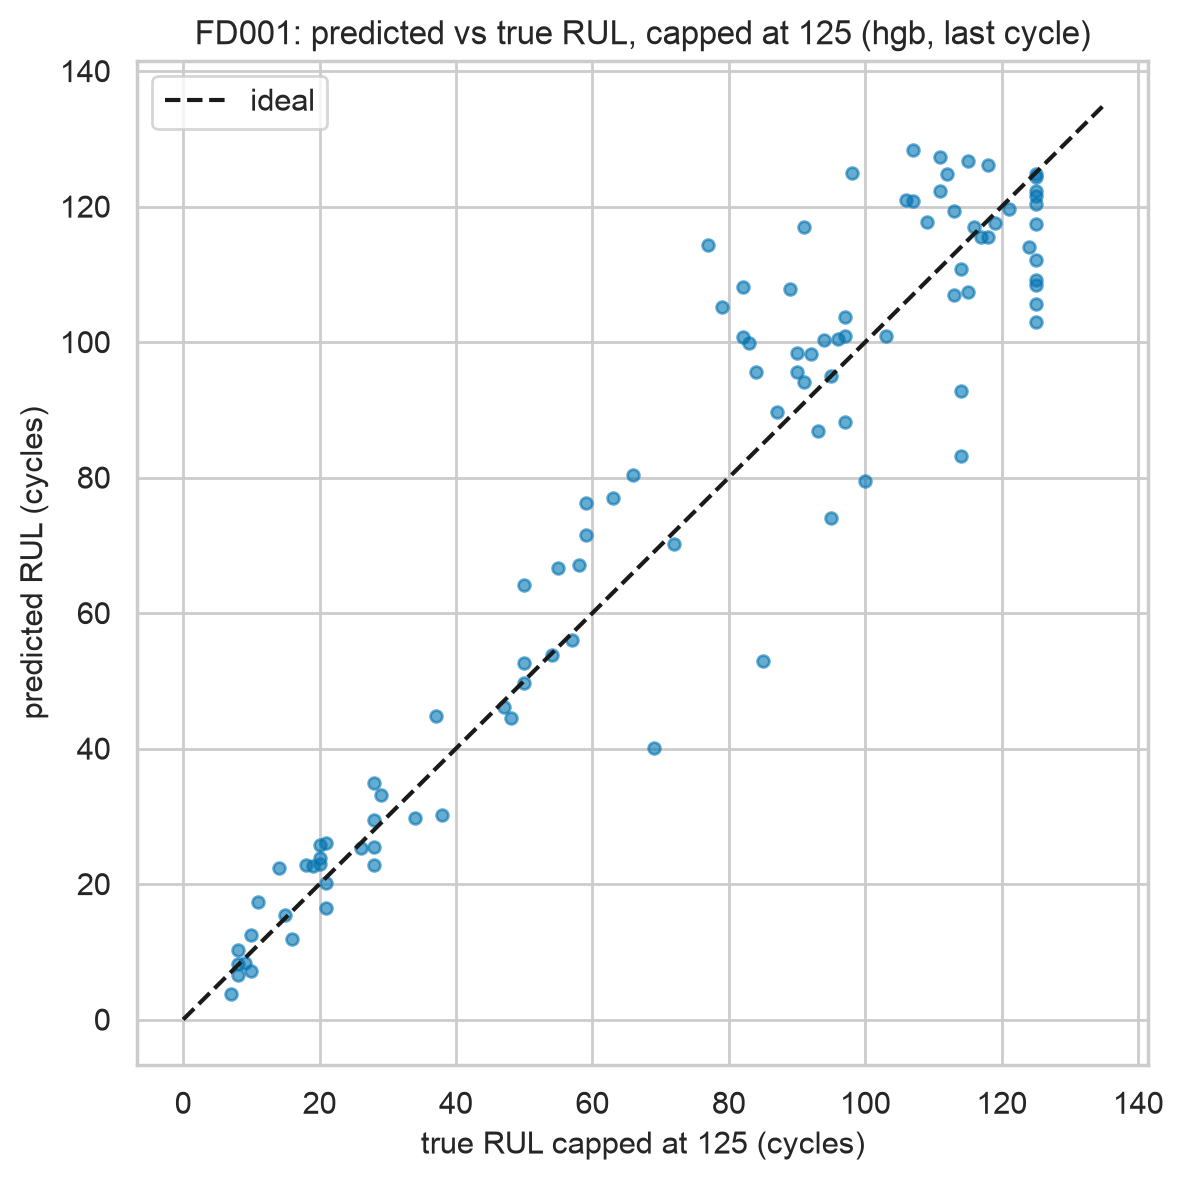

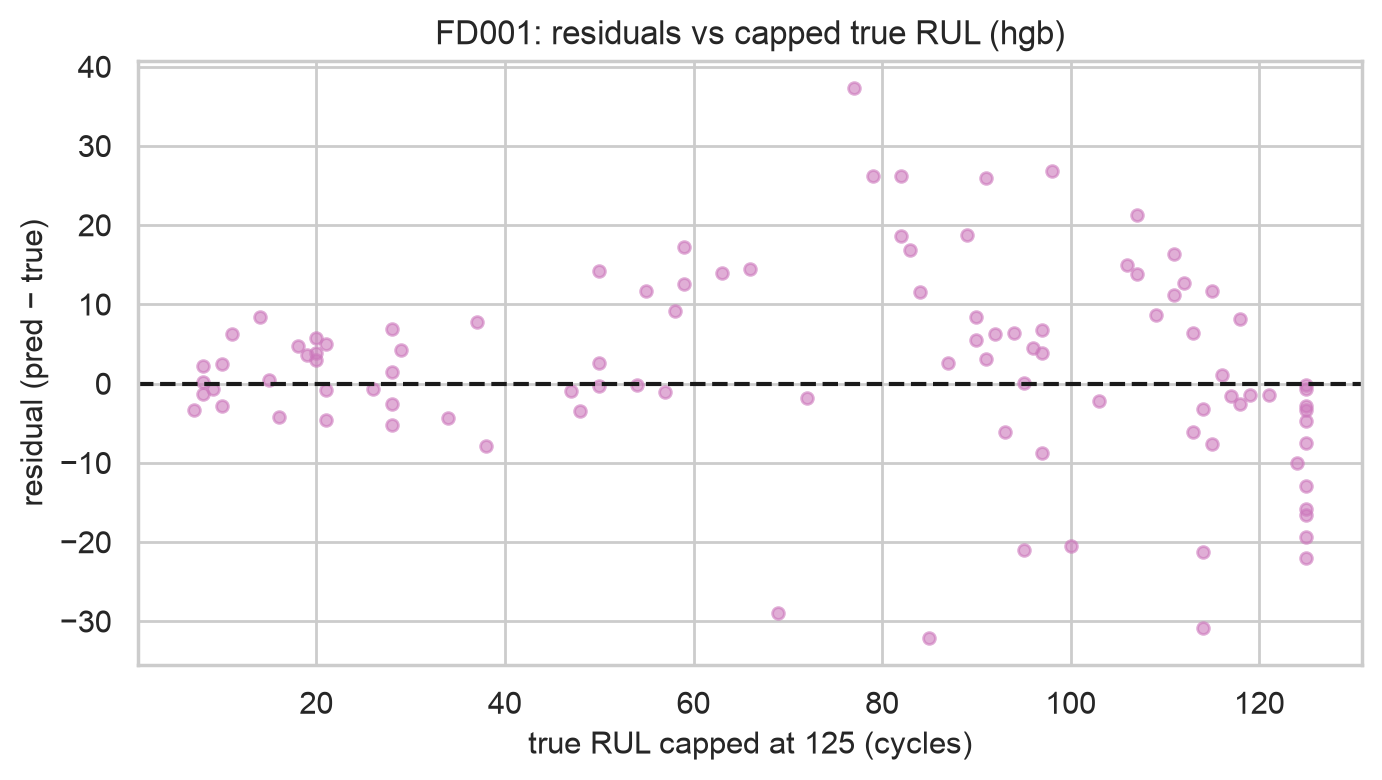

In [2]:
import glob
from IPython.display import Image, display
figs=sorted(glob.glob('../figures/FD001_pred_vs_true*.png') or glob.glob('figures/FD001_pred_vs_true*.png'))
for f in figs[:2]+sorted(glob.glob('../figures/FD001_residuals*.png') or glob.glob('figures/FD001_residuals*.png'))[:1]:
    display(Image(filename=f,width=650))